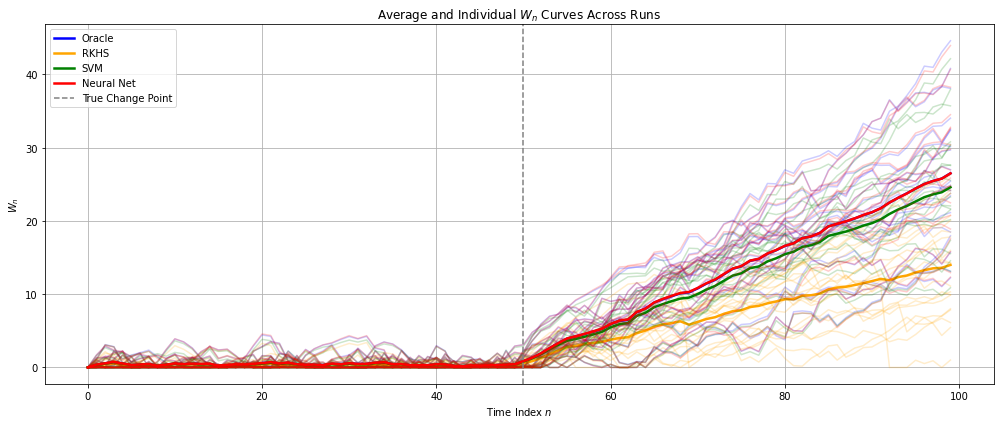

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize
import os

# === Oracle CUSUM ===
class OracleCUSUM:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.threshold = threshold

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = np.log(self.f1(stream[n]) / self.f0(stream[n]))
            W[n] = max(0, W[n-1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# === RKHS-based Estimator and CUSUM ===
class RKHSBasedCUSUM:
    def __init__(self, sigma=1.0, lambda_reg=1e-2, threshold=5.0):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.threshold = threshold

    def fit(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, None], X_p[:, None], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, None], X_p[:, None], gamma=gamma)
        n_p = K_PP.shape[0]
        n_q = K_QP.shape[0]

        def loss(alpha):
            g_q = K_QP @ alpha
            g_p = K_PP @ alpha
            g_p = np.clip(g_p, 1e-8, None)
            return -np.mean(np.log(g_p)) + np.mean(g_q) + self.lambda_reg * alpha @ K_PP @ alpha

        alpha0 = np.ones(n_p) / n_p
        res = minimize(loss, alpha0, method='L-BFGS-B')
        self.alpha = res.x
        self.X_p = X_p
        self.gamma = gamma

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            k = np.exp(-self.gamma * (stream[n] - self.X_p)**2)
            g_hat = np.dot(k, self.alpha)
            llr = np.log(np.clip(g_hat, 1e-8, None))
            W[n] = max(0, W[n-1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# === SVM Regressor-based CUSUM ===
class SVMBasedCUSUM:
    def __init__(self, threshold=5.0):
        self.model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
        self.threshold = threshold

    def fit(self, X_p, X_q):
        X = np.concatenate([X_p, X_q])[:, None]
        y = np.concatenate([np.log(1e-8 + norm.pdf(X_p, loc=1.0) / norm.pdf(X_p, loc=0.0)),
                            np.log(1e-8 + norm.pdf(X_q, loc=1.0) / norm.pdf(X_q, loc=0.0))])
        self.model.fit(X, y)

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = self.model.predict([[stream[n]]])[0]
            W[n] = max(0, W[n-1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# === Neural Net Regressor-based CUSUM ===
class NNBasedCUSUM:
    def __init__(self, threshold=5.0):
        self.model = MLPRegressor(hidden_layer_sizes=(32, 32), activation='relu', max_iter=1000)
        self.threshold = threshold

    def fit(self, X_p, X_q):
        X = np.concatenate([X_p, X_q])[:, None]
        y = np.concatenate([np.log(1e-8 + norm.pdf(X_p, loc=1.0) / norm.pdf(X_p, loc=0.0)),
                            np.log(1e-8 + norm.pdf(X_q, loc=1.0) / norm.pdf(X_q, loc=0.0))])
        self.model.fit(X, y)

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = self.model.predict([[stream[n]]])[0]
            W[n] = max(0, W[n-1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# === Simulation ===
n_trials = 20
n_total = 100
changepoint = 50
threshold = 5.0
train_size = 300
sigma = 1.0
lambda_reg = 1e-2

f0_pdf = lambda x: norm.pdf(x, loc=0.0, scale=1.0)
f1_pdf = lambda x: norm.pdf(x, loc=1.0, scale=1.0)

W_oracle_list, W_rkhs_list, W_svm_list, W_nn_list = [], [], [], []

for seed in range(n_trials):
    np.random.seed(seed)
    X_p = np.random.normal(1.0, 1.0, train_size)
    X_q = np.random.normal(0.0, 1.0, train_size)

    rkhs_model = RKHSBasedCUSUM(threshold=threshold, sigma=sigma, lambda_reg=lambda_reg)
    svm_model = SVMBasedCUSUM(threshold=threshold)
    nn_model = NNBasedCUSUM(threshold=threshold)
    oracle = OracleCUSUM(f0_pdf, f1_pdf, threshold)

    rkhs_model.fit(X_p, X_q)
    svm_model.fit(X_p, X_q)
    nn_model.fit(X_p, X_q)

    stream = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])

    W_oracle, _ = oracle.run(stream)
    W_rkhs, _ = rkhs_model.run(stream)
    W_svm, _ = svm_model.run(stream)
    W_nn, _ = nn_model.run(stream)

    W_oracle_list.append(W_oracle)
    W_rkhs_list.append(W_rkhs)
    W_svm_list.append(W_svm)
    W_nn_list.append(W_nn)

# === Plotting ===
W_oracle_array = np.vstack(W_oracle_list)
W_rkhs_array = np.vstack(W_rkhs_list)
W_svm_array = np.vstack(W_svm_list)
W_nn_array = np.vstack(W_nn_list)

plt.figure(figsize=(14, 6))

for w in W_oracle_array:
    plt.plot(w, color='blue', alpha=0.2)
plt.plot(W_oracle_array.mean(axis=0), color='blue', linewidth=2.5, label="Oracle")

for w in W_rkhs_array:
    plt.plot(w, color='orange', alpha=0.2)
plt.plot(W_rkhs_array.mean(axis=0), color='orange', linewidth=2.5, label="RKHS")

for w in W_svm_array:
    plt.plot(w, color='green', alpha=0.2)
plt.plot(W_svm_array.mean(axis=0), color='green', linewidth=2.5, label="SVM")

for w in W_nn_array:
    plt.plot(w, color='red', alpha=0.2)
plt.plot(W_nn_array.mean(axis=0), color='red', linewidth=2.5, label="Neural Net")

plt.axvline(changepoint, color='gray', linestyle='--', label='True Change Point')
plt.title("Average and Individual $W_n$ Curves Across Runs")
plt.xlabel("Time Index $n$")
plt.ylabel("$W_n$")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/NN_Wn_multiruns.png", dpi=300, bbox_inches='tight')
plt.show()


In [2]:
# Running a harder problem
np.random.seed(4)
n_total = 100
changepoint = 50
threshold = 5.0
train_size = 300

# Pre: N(0,1), Post: Mixture of N(-2,1) and N(2,1)
X_q = np.random.normal(0.0, 1.0, train_size)
X_p = np.concatenate([
    np.random.normal(-1.0, 1.0, train_size // 2),
    np.random.normal(1.0, 1.0, train_size // 2)
])
stream = np.concatenate([
    np.random.normal(0.0, 1.0, changepoint),
    np.concatenate([
        np.random.normal(-2.0, 1.0, (n_total - changepoint) // 2),
        np.random.normal(2.0, 1.0, (n_total - changepoint) // 2)
    ])
])

f0_pdf = lambda x: norm.pdf(x, loc=0.0, scale=1.0)
f1_pdf = lambda x: 0.5 * norm.pdf(x, loc=-2.0, scale=1.0) + 0.5 * norm.pdf(x, loc=2.0, scale=1.0)

# Reinitialize detectors
oracle = CUSUM(f0_pdf, f1_pdf, threshold)
rkhs_model = RKHSBasedCUSUM(threshold=threshold)
svm_model = SVMBasedCUSUM(threshold=threshold)
nn_model = NNBasedCUSUM(threshold=threshold)

# Fit and run all models
rkhs_model.fit(X_p, X_q)
svm_model.fit(X_p, X_q)
nn_model.fit(X_p, X_q)

W_oracle, _, tau_oracle = oracle.run(stream)
W_rkhs, tau_rkhs = rkhs_model.run(stream)
W_svm, tau_svm = svm_model.run(stream)
W_nn, tau_nn = nn_model.run(stream)

# Plot
plt.figure(figsize=(12, 5))
plt.plot(W_oracle, label="Oracle", color='blue', linewidth=2)
plt.plot(W_rkhs, label="RKHS", color='orange', linewidth=2)
plt.plot(W_svm, label="SVM", color='green', linewidth=2)
plt.plot(W_nn, label="Neural Net", color='red', linewidth=2)
plt.axvline(changepoint, color='gray', linestyle='--', label='True Change Point')
plt.title("Single Run $W_n$ Comparison - Challenging Scenario")
plt.xlabel("Time Index $n$")
plt.ylabel("$W_n$")
plt.grid(True)
plt.legend()
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/Estimator_failure_case.png", dpi=300, bbox_inches='tight')
plt.show()


NameError: name 'CUSUM' is not defined

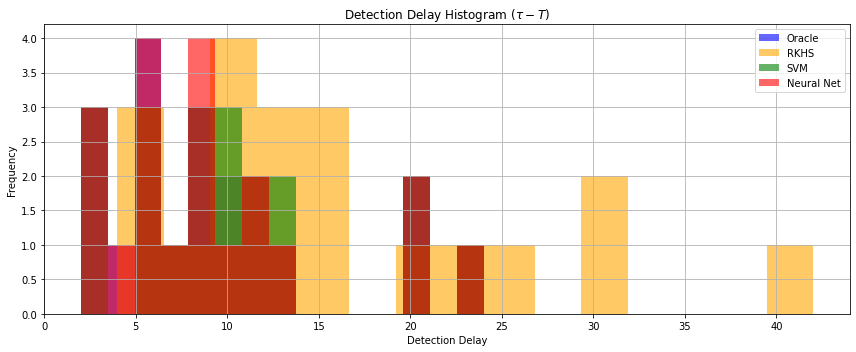

In [ ]:
# Redefine missing configuration variables
n_trials = 20
n_total = 100
changepoint = 50
threshold = 5.0
train_size = 300
sigma = 1.0
lambda_reg = 1e-2

# Redefine density functions
f0_pdf = lambda x: norm.pdf(x, loc=0.0, scale=1.0)
f1_pdf = lambda x: norm.pdf(x, loc=1.0, scale=1.0)

# Now re-run the experiment and plotting code
W_oracle_list, W_rkhs_list, W_svm_list, W_nn_list = [], [], [], []

for seed in range(n_trials):
    np.random.seed(seed)
    X_p = np.random.normal(1.0, 1.0, train_size)
    X_q = np.random.normal(0.0, 1.0, train_size)

    rkhs_model = RKHSBasedCUSUM(threshold=threshold, sigma=sigma, lambda_reg=lambda_reg)
    svm_model = SVMBasedCUSUM(threshold=threshold)
    nn_model = NNBasedCUSUM(threshold=threshold)
    oracle = OracleCUSUM(f0_pdf, f1_pdf, threshold)

    rkhs_model.fit(X_p, X_q)
    svm_model.fit(X_p, X_q)
    nn_model.fit(X_p, X_q)

    stream = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])

    W_oracle, _ = oracle.run(stream)
    W_rkhs, _ = rkhs_model.run(stream)
    W_svm, _ = svm_model.run(stream)
    W_nn, _ = nn_model.run(stream)

    W_oracle_list.append(W_oracle)
    W_rkhs_list.append(W_rkhs)
    W_svm_list.append(W_svm)
    W_nn_list.append(W_nn)

# Compute detection delays
def compute_tau(W, threshold):
    for n in range(len(W)):
        if W[n] >= threshold:
            return n
    return len(W)

detection_delays = {
    "Oracle": [compute_tau(W, threshold) - changepoint for W in W_oracle_list],
    "RKHS": [compute_tau(W, threshold) - changepoint for W in W_rkhs_list],
    "SVM": [compute_tau(W, threshold) - changepoint for W in W_svm_list],
    "NN": [compute_tau(W, threshold) - changepoint for W in W_nn_list],
}

# Plot Detection Delay Histogram
plt.figure(figsize=(12, 5))
plt.hist(detection_delays["Oracle"], bins=15, alpha=0.6, label="Oracle", color="blue")
plt.hist(detection_delays["RKHS"], bins=15, alpha=0.6, label="RKHS", color="orange")
plt.hist(detection_delays["SVM"], bins=15, alpha=0.6, label="SVM", color="green")
plt.hist(detection_delays["NN"], bins=15, alpha=0.6, label="Neural Net", color="red")
plt.title("Detection Delay Histogram ($\\tau - T$)")
plt.xlabel("Detection Delay")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/NN_DD_histograms.png", dpi=300, bbox_inches='tight')
plt.show()
